In [19]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

edf_path = Path("../data/raw/chb01_03.edf")

assert edf_path.exists(), f"File not found: {edf_path}"

raw = mne.io.read_raw_edf(
    edf_path,
    preload=True,
    verbose=False
)

print("File loaded successfully!")
print(f"Sampling rate: {raw.info['sfreq']} Hz")
print(f"Number of channels: {len(raw.ch_names)}")
print(f"Duration: {raw.times[-1]:,.2f} seconds")
print(f"Duration: {raw.times[-1] / 60:.2f} minutes")
print(f"Channel names: {raw.ch_names}")
print(f"Channel types: {raw.get_channel_types()}")
print(f"Data shape: {raw.get_data().shape}")

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_18300\2229413045.py:11: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(


File loaded successfully!
Sampling rate: 256.0 Hz
Number of channels: 23
Duration: 3,600.00 seconds
Duration: 60.00 minutes
Channel names: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
Channel types: ['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg']
Data shape: (23, 921600)


In [44]:
eeg_data = raw.get_data()

print("Array dimensions:", eeg_data.shape)

# Inspect the first 10 samples of the first 3 channels
print(eeg_data[:3, :10])

# Basic statistics for each channel
channel_stats = pd.DataFrame({
    "channel": raw.ch_names,
    "mean": eeg_data.mean(axis=1),
    "std": eeg_data.std(axis=1),
    "min": eeg_data.min(axis=1),
    "max": eeg_data.max(axis=1),
})


channel_stats

Array dimensions: (23, 921600)
[[-1.77777778e-05  1.95360195e-07  1.95360195e-07  5.86080586e-07
   1.95360195e-07 -1.36752137e-06 -2.14896215e-06  5.86080586e-07
   2.93040293e-06 -5.86080586e-07]
 [ 3.92673993e-05  1.95360195e-07  1.95360195e-07  1.95360195e-07
   1.95360195e-07  1.75824176e-06  1.75824176e-06 -9.76800977e-07
  -2.14896215e-06  1.36752137e-06]
 [-3.71184371e-06  1.95360195e-07  1.95360195e-07  1.95360195e-07
   1.95360195e-07  1.95360195e-07  1.95360195e-07  1.95360195e-07
   1.95360195e-07  1.95360195e-07]]


,channel,mean,std,min,max
0,FP1-F7,1.792972e-07,0.000041,-0.000480,0.000500
1,F7-T7,1.699668e-07,0.000033,-0.000282,0.000306
2,T7-P7,2.115262e-07,0.000040,-0.000314,0.000310
3,P7-O1,2.129045e-07,0.000033,-0.000206,0.000199
4,FP1-F3,1.915001e-07,0.000047,-0.000513,0.000557
5,F3-C3,1.780686e-07,0.000047,-0.000431,0.000349
6,C3-P3,2.059151e-07,0.000034,-0.000317,0.000363
7,P3-O1,2.027239e-07,0.000042,-0.000386,0.000343
8,FP2-F4,1.950278e-07,0.000046,-0.000536,0.000451
9,F4-C4,1.785070e-07,0.000046,-0.000554,0.000395


In [48]:
eeg_microvolts = eeg_data * 1_000_000

print(eeg_microvolts[:3, :10])

[[-17.77777778   0.1953602    0.1953602    0.58608059   0.1953602
   -1.36752137  -2.14896215   0.58608059   2.93040293  -0.58608059]
 [ 39.26739927   0.1953602    0.1953602    0.1953602    0.1953602
    1.75824176   1.75824176  -0.97680098  -2.14896215   1.36752137]
 [ -3.71184371   0.1953602    0.1953602    0.1953602    0.1953602
    0.1953602    0.1953602    0.1953602    0.1953602    0.1953602 ]]


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


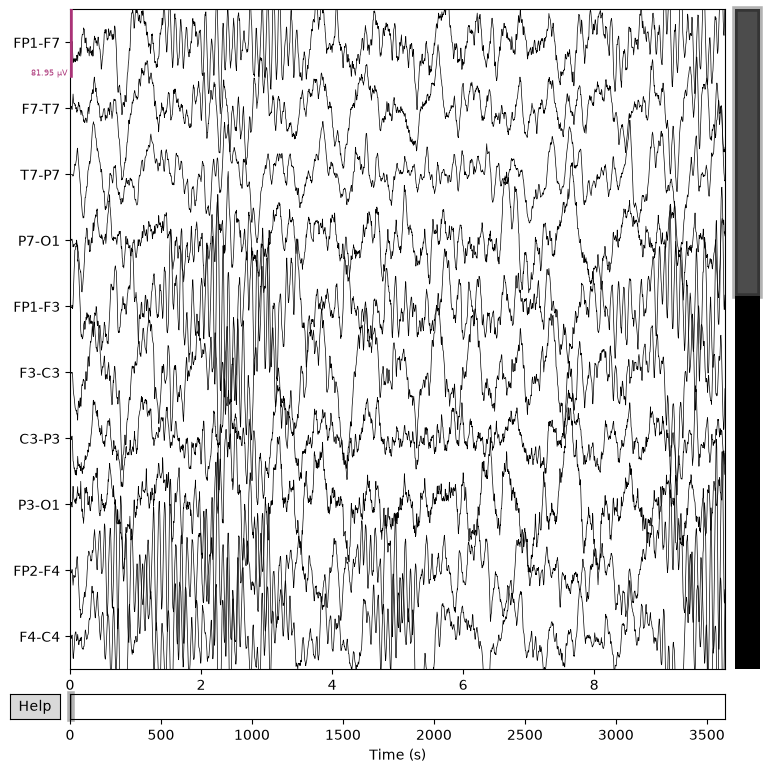

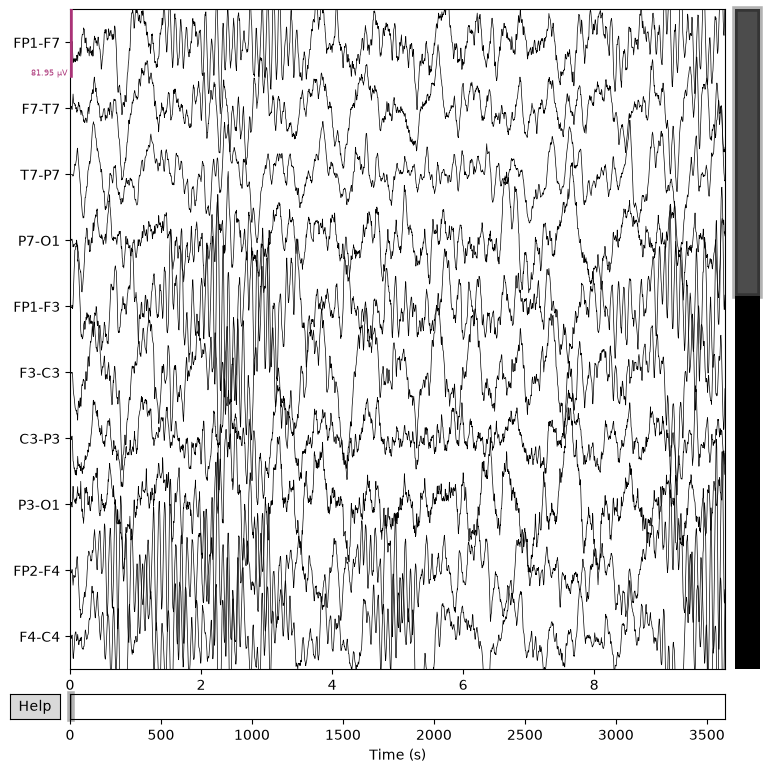

In [46]:
raw.plot(
    start=0,
    duration=10,
    n_channels=min(10, len(raw.ch_names)),
    scalings="auto",
    title="CHB01_03 - First 10 Seconds",
    show=True
)

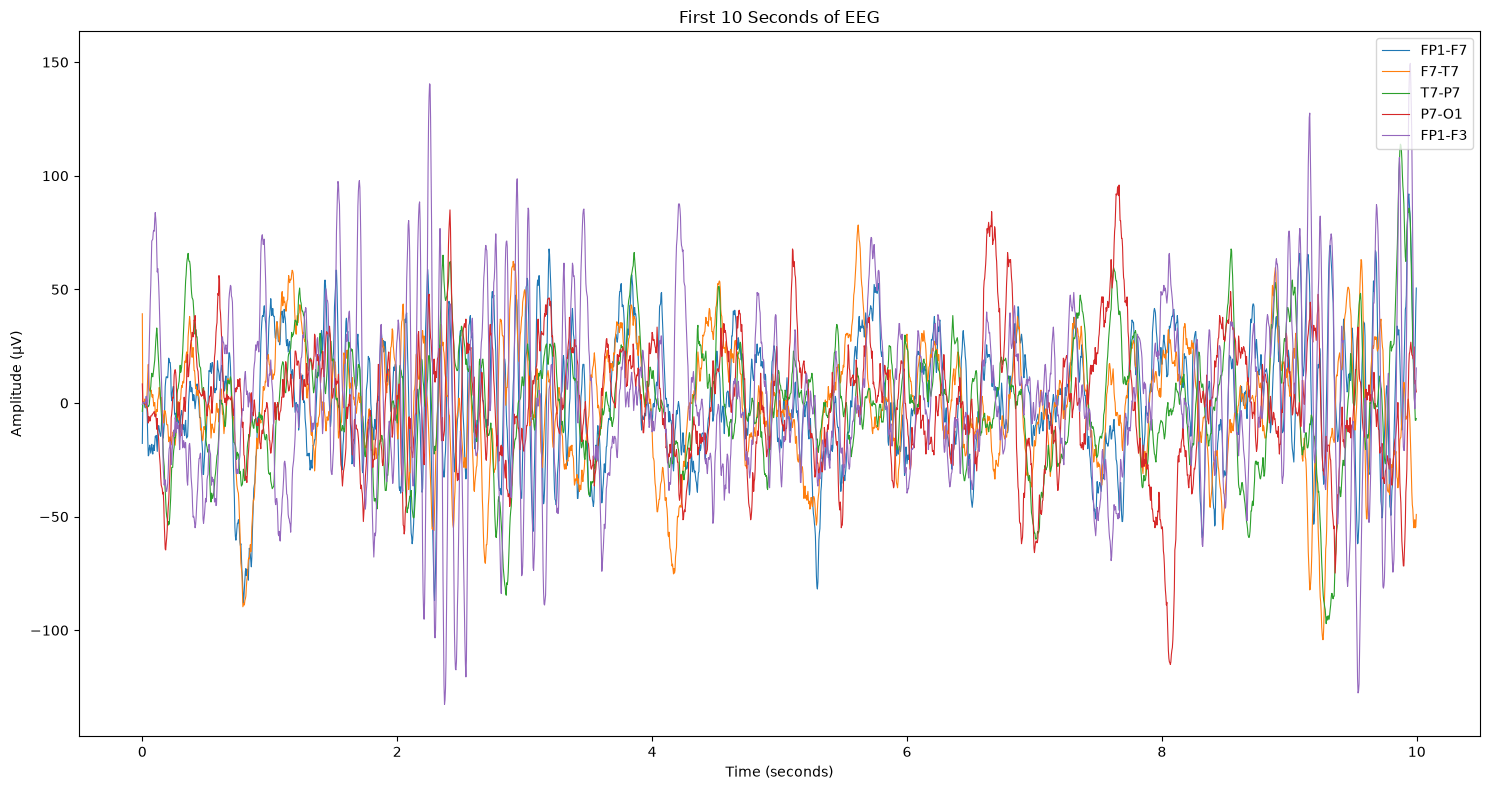

In [42]:
sampling_rate = raw.info["sfreq"]
duration_seconds = 10

number_of_samples = int(sampling_rate * duration_seconds)

time = np.arange(number_of_samples) / sampling_rate

plt.figure(figsize=(15, 8))

for channel_index in range(min(5, len(raw.ch_names))):
    plt.plot(
        time,
        eeg_microvolts[channel_index, :number_of_samples],
        label=raw.ch_names[channel_index],
        linewidth=0.8
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title("First 10 Seconds of EEG")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


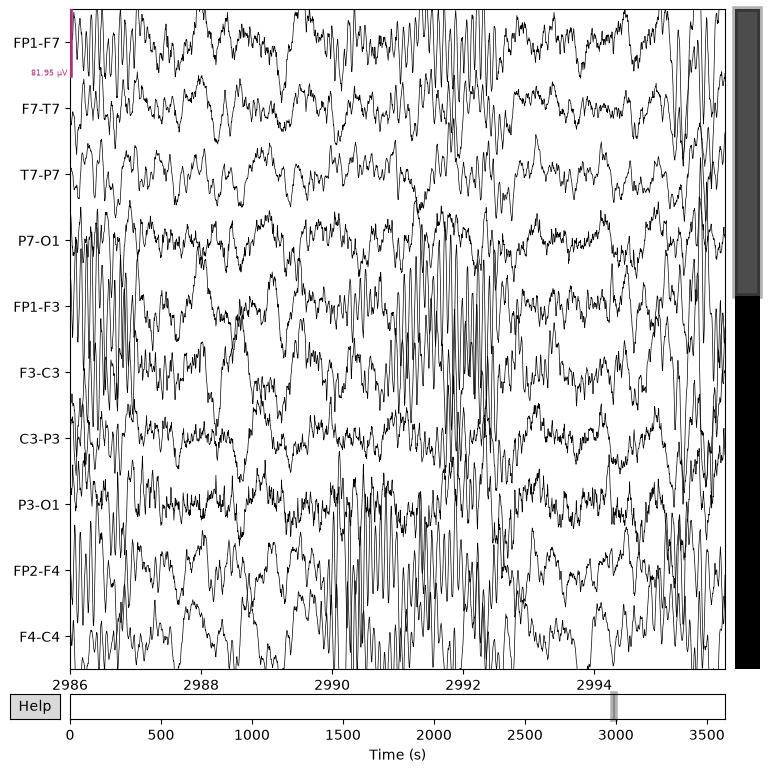

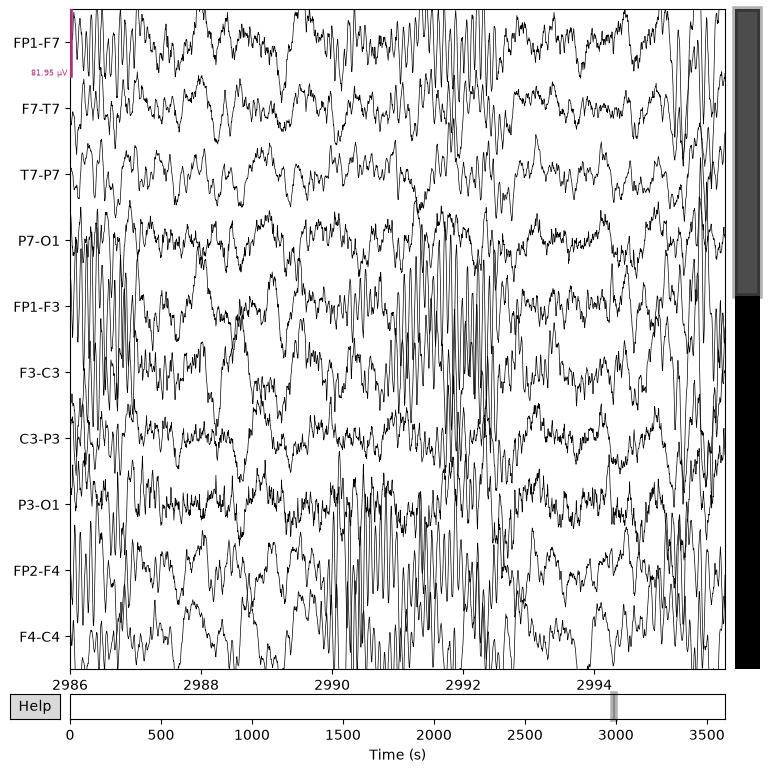

In [62]:
seizure_start = 2996
seizure_end = 3036

raw.plot(
    start=seizure_start - 10,
    duration=10,
    n_channels=min(10, len(raw.ch_names)),
    scalings="auto",
    title="EEG Before Annotated Seizure Onset",
    show=True
)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


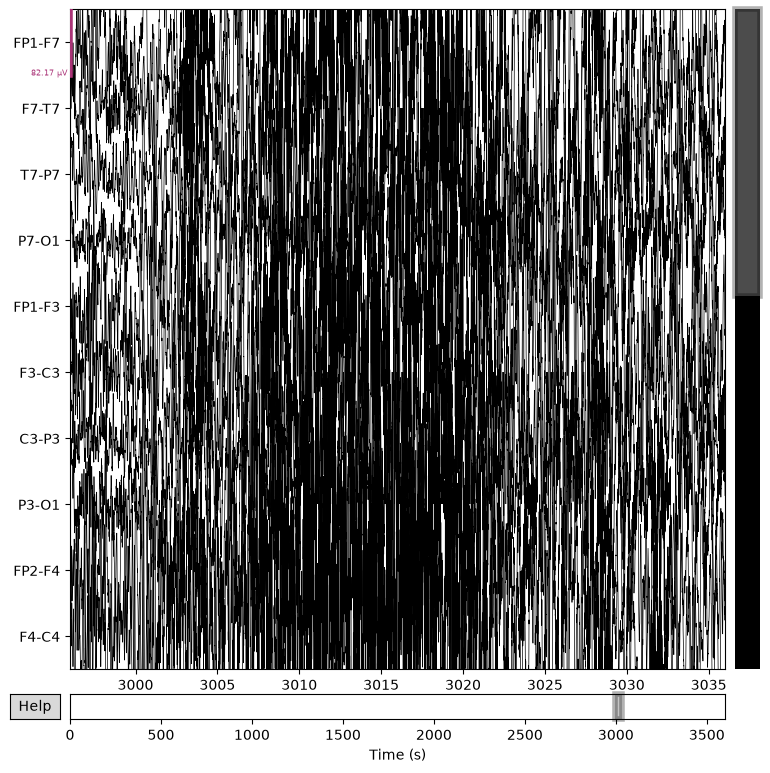

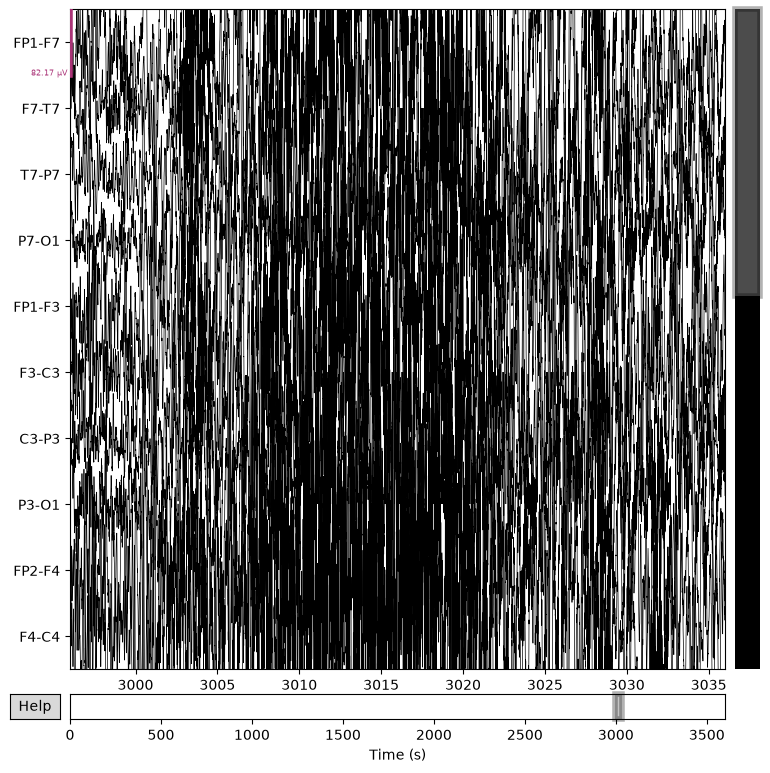

In [56]:
raw.plot(
    start=seizure_start,
    duration=seizure_end-seizure_start,
    n_channels=min(10, len(raw.ch_names)),
    scalings="auto",
    title="EEG During Annotated Seizure",
    show=True
)

In [60]:
annotations = pd.DataFrame([
    {
        "event": "seizure",
        "start_seconds": 2996,
        "end_seconds": 3036,
    }
])

annotations["duration_seconds"] = (
    annotations["end_seconds"] - annotations["start_seconds"]
)

display(annotations)

,event,start_seconds,end_seconds,duration_seconds
0,seizure,2996,3036,40


In [64]:
window_seconds = 5
samples_per_window = int(
    raw.info["sfreq"] * window_seconds
)

number_of_channels = len(raw.ch_names)

# Extract the first five seconds
first_window = eeg_data[:, :samples_per_window]

print("Window shape:", first_window.shape)
print("Channels:", number_of_channels)
print("Samples per channel:", samples_per_window)

Window shape: (23, 1280)
Channels: 23
Samples per channel: 1280


In [84]:
total_samples = eeg_data.shape[1]

number_of_windows = total_samples // samples_per_window

windows = eeg_data[
    :,
    :number_of_windows * samples_per_window
].reshape(
    number_of_channels,
    number_of_windows,
    samples_per_window
).transpose(1, 0, 2)

print("All windows shape:", windows.shape)

All windows shape: (720, 23, 1280)
